<a href="https://colab.research.google.com/github/yu-nishiuchi-jk1pic/yu-nishiuchi-jk1pic.github.io/blob/main/20261022gaaspn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

# 正規表現パターン
volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V' # 電圧抽出用
num_pattern = r'(\d{4})'                   # 4桁の数字抽出用

# データを分けるためのリスト
group_main = [] # 0085以下（または4桁の数字がない）のファイル
group_p3 = []   # 0086以上のファイル (p3)

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # 4桁の数字があるか確認し、0086以上か判定
        is_p3 = False
        if num_match:
            file_num = int(num_match.group(1)) # 例: '0086' -> 86
            if file_num >= 86:
                is_p3 = True

        # 条件に応じて別々のリストに格納
        if is_p3:
            # 「p3と名付ける」ため、凡例ラベルの先頭に p3_ を付与
            group_p3.append((file_path, f"p3_{label_str}", voltage_val))
        else:
            group_main.append((file_path, label_str, voltage_val))


# グラフを描画する共通関数
def plot_group(data_group, title):
    if not data_group:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    # 電圧値でソート
    data_group.sort(key=lambda x: x[2])

    voltages = [info[2] for info in data_group]
    norm = mcolors.Normalize(vmin=min(voltages), vmax=max(voltages))
    cmap = cm.viridis

    plt.figure(figsize=(10, 6))

    for file_path, label, voltage in data_group:
        line_color = cmap(norm(voltage))

        with np.load(file_path) as data:
            keys = data.files
            if len(keys) >= 2:
                x = data[keys[0]]
                y = data[keys[1]]
            else:
                y = data[keys[0]]
                x = np.arange(len(y))

        plt.plot(x, y, label=label, color=line_color)

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    plt.title(title)

    # Y軸を指数表記にする設定（前回の引き継ぎ）
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# --- それぞれ別々のグラフとしてプロットを実行 ---

if group_main:
    plot_group(group_main, "Voltage Data Overlay (< 0086)")

if group_p3:
    plot_group(group_p3, "Voltage Data Overlay - p3 (>= 0086)")

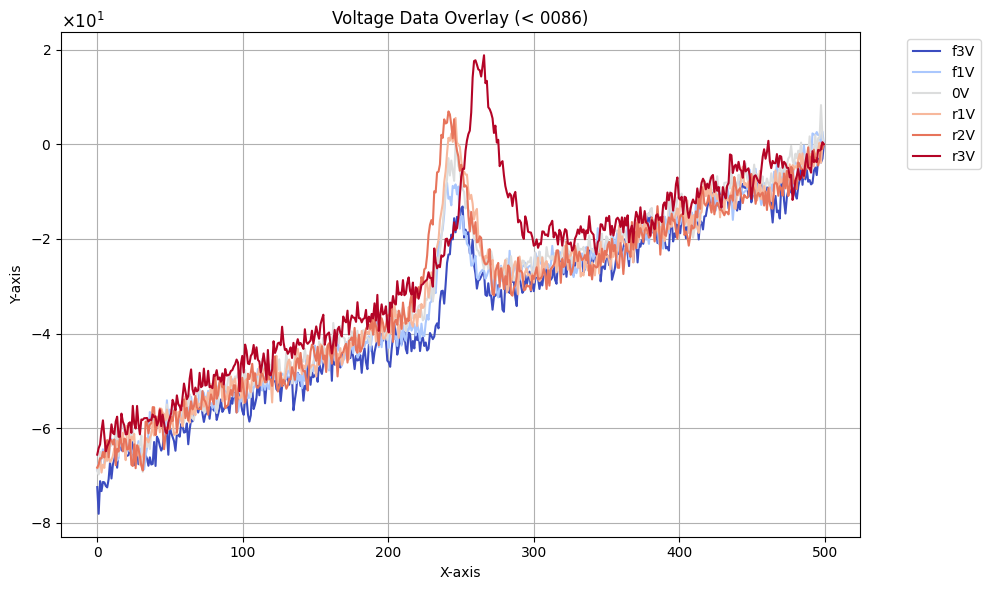

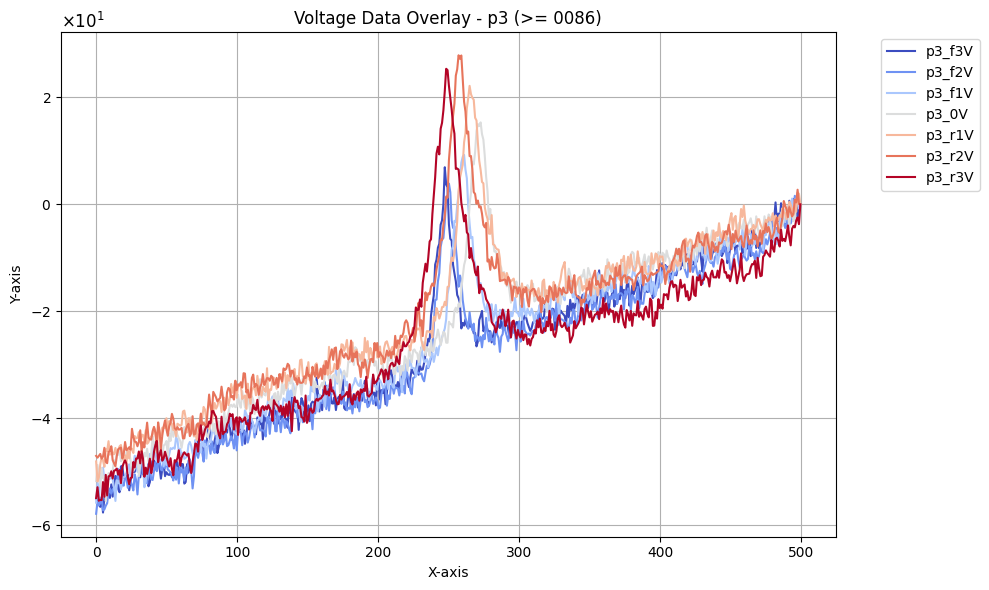

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

dict_main = {}
dict_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # f(順電圧)はプラス、r(逆電圧)はマイナスとして「実効電圧」を定義
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val # 0Vなど

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        # 1つの電圧値につき1ファイルだけを登録
        if is_p3:
            if label_str not in dict_p3:
                dict_p3[label_str] = (file_path, f"p3_{label_str}", effective_v)
        else:
            if label_str not in dict_main:
                dict_main[label_str] = (file_path, label_str, effective_v)

# 辞書からリスト化
group_main = list(dict_main.values())
group_p3 = list(dict_p3.values())

def plot_group(data_group, title):
    if not data_group:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    # 凡例とプロットの順番（降順：f -> 0V -> r の順）
    data_group.sort(key=lambda x: x[2], reverse=True)

    # カラーマップの計算用には全体の最小値・最大値を使用
    voltages = [info[2] for info in data_group]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax:
        vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    # ★ 変更点: coolwarm_r を使用して、マイナス(r)を赤、プラス(f)を青に反転
    cmap = cm.coolwarm_r

    plt.figure(figsize=(10, 6))

    for file_path, label, eff_v in data_group:
        line_color = cmap(norm(eff_v))

        with np.load(file_path) as data:
            keys = data.files
            if len(keys) >= 2:
                x = data[keys[0]]
                y = data[keys[1]]
            else:
                y = data[keys[0]]
                x = np.arange(len(y))

        plt.plot(x, y, label=label, color=line_color)

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    plt.title(title)

    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# プロット実行
if group_main:
    plot_group(group_main, "Voltage Data Overlay (< 0086)")

if group_p3:
    plot_group(group_p3, "Voltage Data Overlay - p3 (>= 0086)")

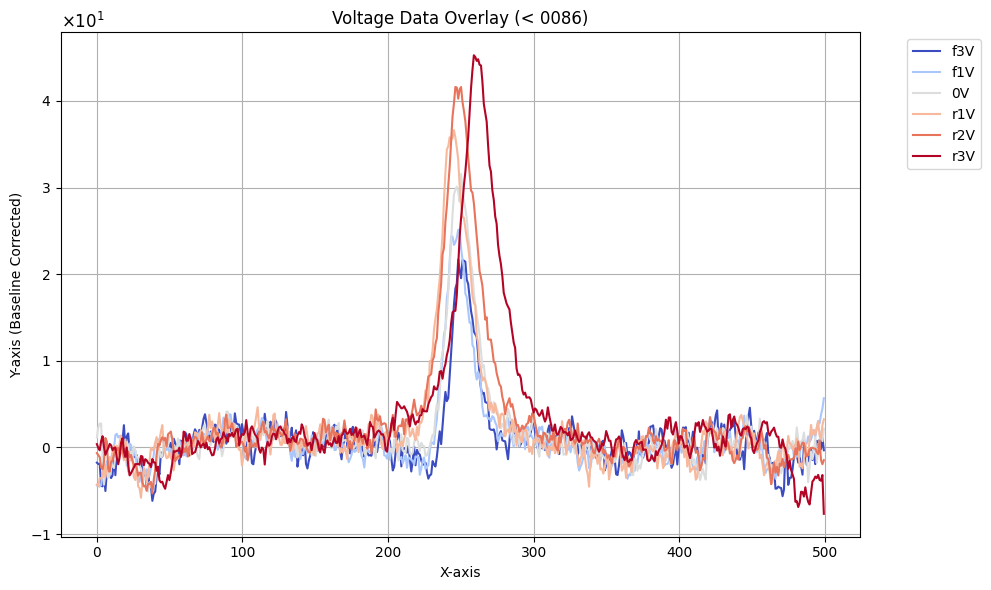

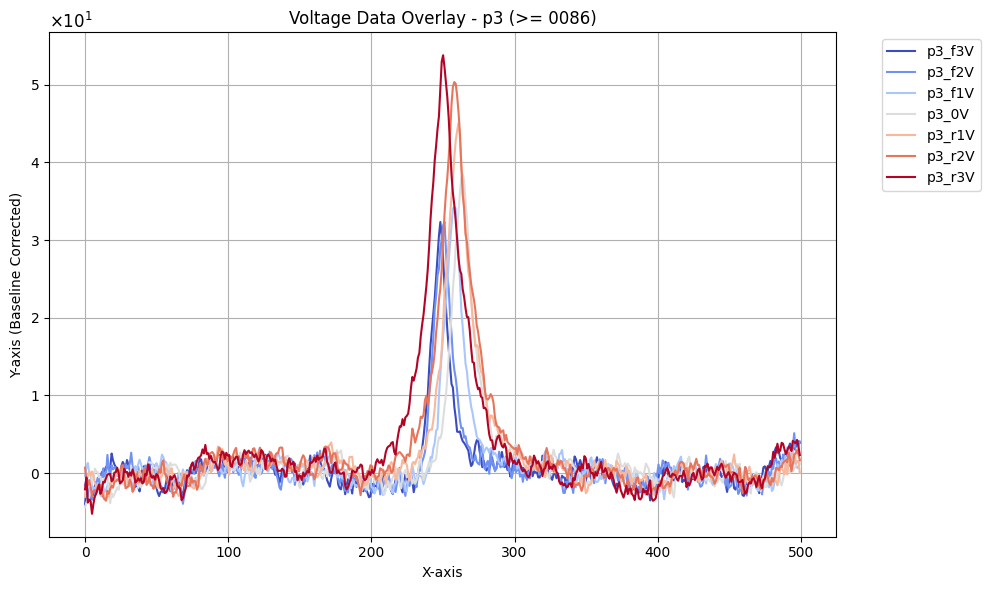

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピークフィッティング用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)

def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.coolwarm_r

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []
        peak_xs = []

        # 1. データの読み込みとガウシアンフィッティングによるピーク検出
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

                # 150 <= X <= 350 の範囲でガウシアンフィット
                mask_peak = (x >= 150) & (x <= 350)
                if np.any(mask_peak):
                    x_peak = x[mask_peak]
                    y_peak = y[mask_peak]

                    # フィッティングの初期値推測
                    a_guess = y_peak.max() - y_peak.min()
                    mu_guess = x_peak[np.argmax(y_peak)]
                    sigma_guess = 10.0
                    c_guess = y_peak.min()
                    p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                    try:
                        # ガウシアンフィット実行
                        popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                        peak_x = popt[1] # フィット結果のμ(中心座標)
                    except RuntimeError:
                        # 収束しなかった場合は最大値のX座標を使用
                        peak_x = mu_guess
                else:
                    peak_x = np.mean(x)

                data_list.append((x, y, peak_x))
                peak_xs.append(peak_x)

        if not data_list:
            continue

        # 2. ピーク位置を合わせるための基準Xを決める（平均ピーク位置）
        target_peak_x = np.mean(peak_xs)

        base_x = data_list[0][0]
        common_x = np.linspace(base_x.min(), base_x.max(), len(base_x))
        aligned_ys = []

        # 3. 横軸を揃えて補間し、平均をとる
        for x, y, peak_x in data_list:
            shift_amount = target_peak_x - peak_x
            shifted_x = x + shift_amount

            f_interp = interp1d(shifted_x, y, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # 4. ベースラインの線形フィッティングと引き算
        base_mask = ((valid_x >= 0) & (valid_x <= 150)) | (valid_x >= 350)

        if np.any(base_mask):
            poly_coeffs = np.polyfit(valid_x[base_mask], valid_y[base_mask], 1)
            baseline_y = np.polyval(poly_coeffs, valid_x)
            final_y = valid_y - baseline_y
        else:
            final_y = valid_y

        # 5. プロット
        line_color = cmap(norm(eff_v))
        plt.plot(valid_x, final_y, label=label, color=line_color)

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)

    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

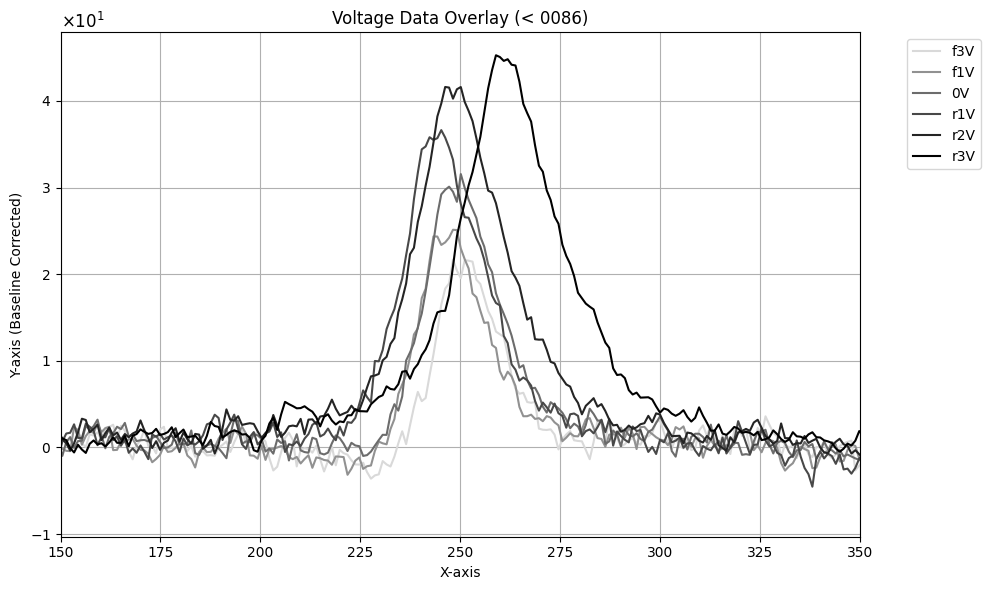

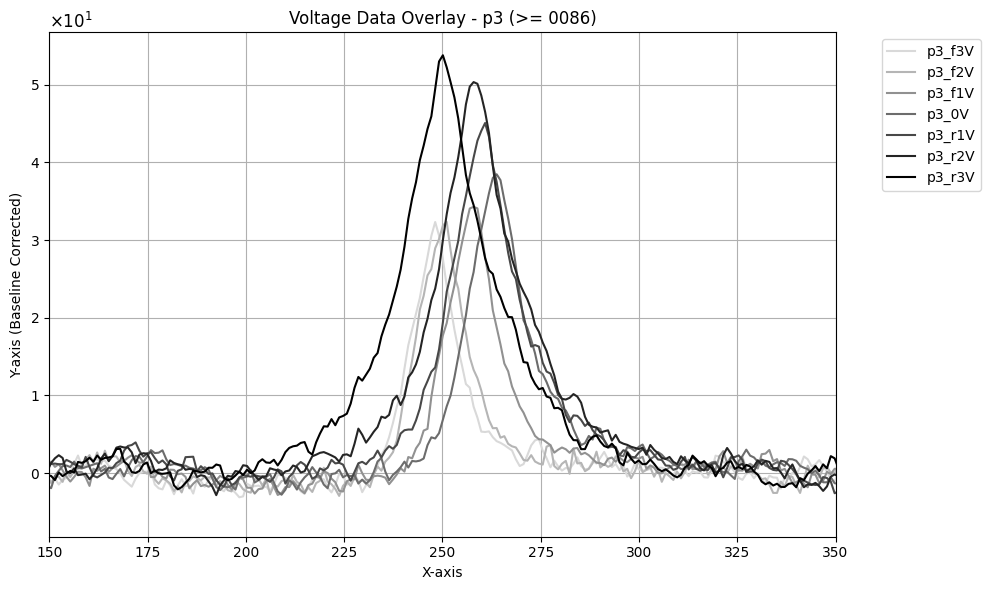

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピークフィッティング用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)

def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    # ★ カラーマップをグレースケール（黒→白）に変更
    cmap = cm.gray

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []
        peak_xs = []

        # 1. データの読み込みとガウシアンフィッティングによるピーク検出
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

                # 150 <= X <= 350 の範囲でガウシアンフィット
                mask_peak = (x >= 150) & (x <= 350)
                if np.any(mask_peak):
                    x_peak = x[mask_peak]
                    y_peak = y[mask_peak]

                    a_guess = y_peak.max() - y_peak.min()
                    mu_guess = x_peak[np.argmax(y_peak)]
                    sigma_guess = 10.0
                    c_guess = y_peak.min()
                    p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                    try:
                        popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                        peak_x = popt[1]
                    except RuntimeError:
                        peak_x = mu_guess
                else:
                    peak_x = np.mean(x)

                data_list.append((x, y, peak_x))
                peak_xs.append(peak_x)

        if not data_list:
            continue

        # 2. ピーク位置を合わせるための基準Xを決める
        target_peak_x = np.mean(peak_xs)

        base_x = data_list[0][0]
        common_x = np.linspace(base_x.min(), base_x.max(), len(base_x))
        aligned_ys = []

        # 3. 横軸を揃えて補間し、平均をとる
        for x, y, peak_x in data_list:
            shift_amount = target_peak_x - peak_x
            shifted_x = x + shift_amount

            f_interp = interp1d(shifted_x, y, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # 4. ベースラインの線形フィッティングと引き算
        base_mask = ((valid_x >= 0) & (valid_x <= 150)) | (valid_x >= 350)

        if np.any(base_mask):
            poly_coeffs = np.polyfit(valid_x[base_mask], valid_y[base_mask], 1)
            baseline_y = np.polyval(poly_coeffs, valid_x)
            final_y = valid_y - baseline_y
        else:
            final_y = valid_y

        # ★ 5. プロット（純白で見えなくなるのを防ぐため、0.0〜0.85の範囲にスケーリング）
        color_val = norm(eff_v) * 0.85
        line_color = cmap(color_val)

        plt.plot(valid_x, final_y, label=label, color=line_color)

    plt.xlabel("X-axis")
    plt.xlim(150,350)
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)

    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

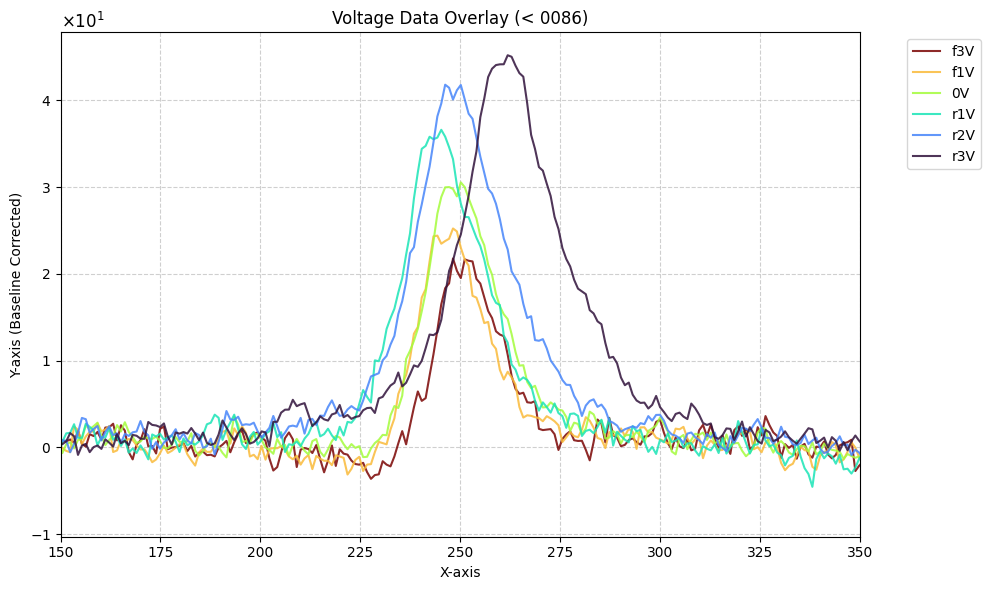

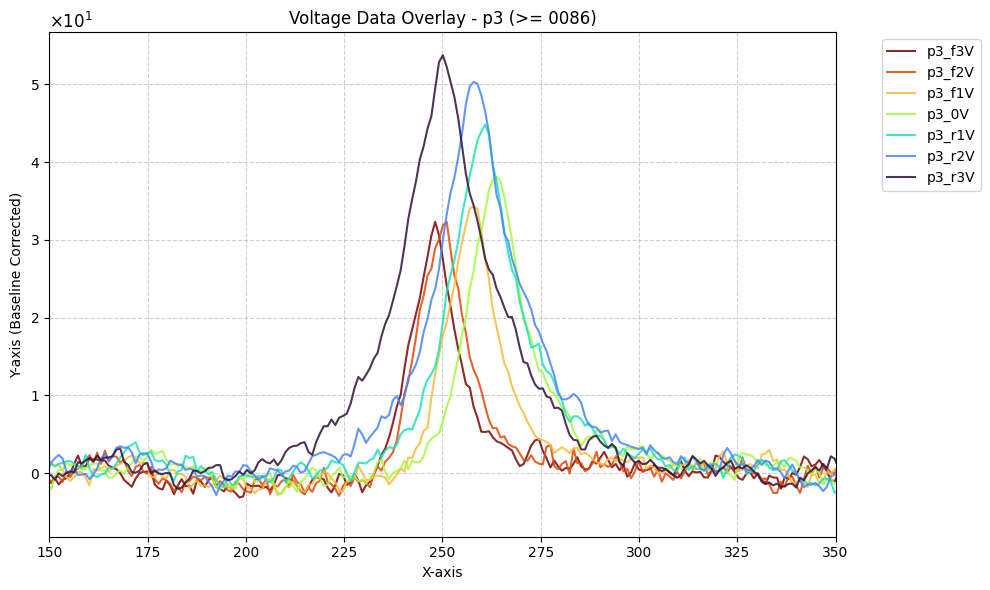

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピークフィッティング用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)

def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.turbo

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []
        peak_xs = []

        # 1. データの読み込みとガウシアンフィッティングによるピーク検出
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

                # ★ 変更点： 200 <= X <= 300 の範囲でガウシアンフィット
                mask_peak = (x >= 200) & (x <= 300)

                if np.any(mask_peak):
                    x_peak = x[mask_peak]
                    y_peak = y[mask_peak]

                    a_guess = y_peak.max() - y_peak.min()
                    mu_guess = x_peak[np.argmax(y_peak)]
                    sigma_guess = 10.0
                    c_guess = y_peak.min()
                    p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                    try:
                        popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                        peak_x = popt[1]
                    except RuntimeError:
                        peak_x = mu_guess
                else:
                    peak_x = np.mean(x)

                data_list.append((x, y, peak_x))
                peak_xs.append(peak_x)

        if not data_list:
            continue

        # 2. ピーク位置を合わせるための基準Xを決める
        target_peak_x = np.mean(peak_xs)

        base_x = data_list[0][0]
        common_x = np.linspace(base_x.min(), base_x.max(), len(base_x))
        aligned_ys = []

        # 3. 横軸を揃えて補間し、平均をとる
        for x, y, peak_x in data_list:
            shift_amount = target_peak_x - peak_x
            shifted_x = x + shift_amount

            f_interp = interp1d(shifted_x, y, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # 4. ベースラインの線形フィッティングと引き算
        # （ピーク範囲を変更したため、ベースライン領域は 0~150, 350~右端 のままとしています）
        base_mask = ((valid_x >= 0) & (valid_x <= 150)) | (valid_x >= 350)

        if np.any(base_mask):
            poly_coeffs = np.polyfit(valid_x[base_mask], valid_y[base_mask], 1)
            baseline_y = np.polyval(poly_coeffs, valid_x)
            final_y = valid_y - baseline_y
        else:
            final_y = valid_y

        # 5. プロット
        line_color = cmap(norm(eff_v))
        plt.plot(valid_x, final_y, label=label, color=line_color, linewidth=1.5, alpha=0.85)

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)
    plt.xlim(150,350)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

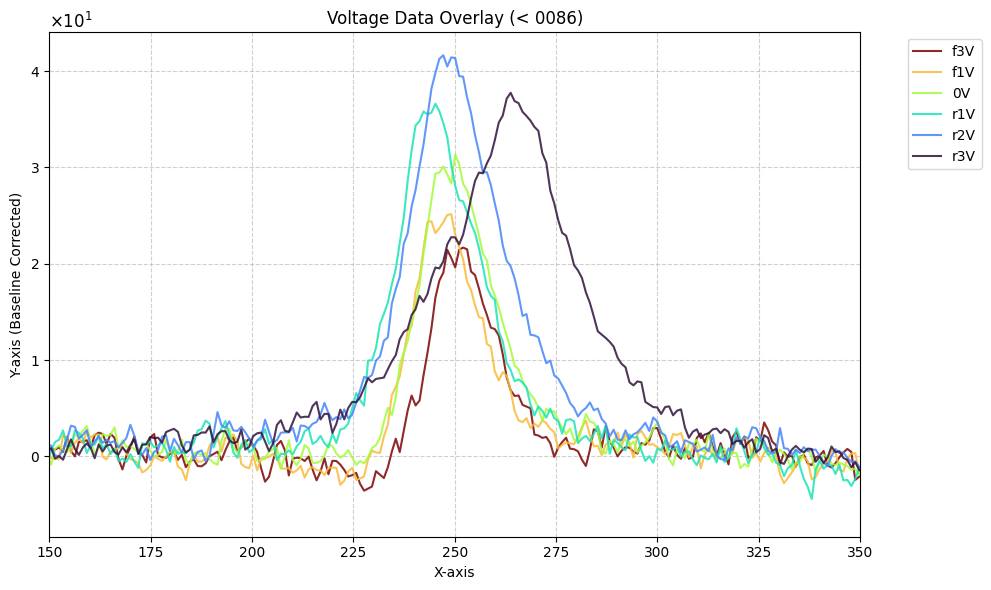

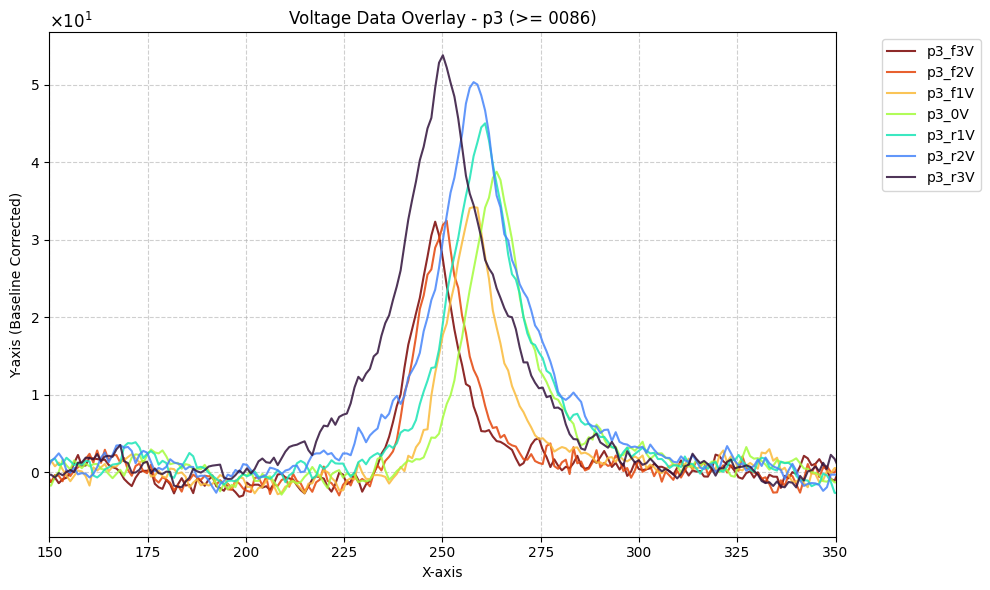

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピークフィッティング用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)

def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.turbo

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []
        peak_xs = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】まずベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】ベースラインを引いたデータに対して、200~300でガウシアンフィット
            mask_peak = (x >= 225) & (x <= 275)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak] # 補正後のyを使用

                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))
            peak_xs.append(peak_x)

        if not data_list:
            continue

        # 【手順3】ピーク位置を合わせる
        target_peak_x = np.mean(peak_xs)
        base_x = data_list[0][0]
        common_x = np.linspace(base_x.min(), base_x.max(), len(base_x))
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            shift_amount = target_peak_x - peak_x
            shifted_x = x + shift_amount

            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 【手順4】横軸を揃えた状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # 【手順5】プロット
        line_color = cmap(norm(eff_v))
        plt.plot(valid_x, valid_y, label=label, color=line_color, linewidth=1.5, alpha=0.85)

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)
    plt.xlim(150,350)

    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

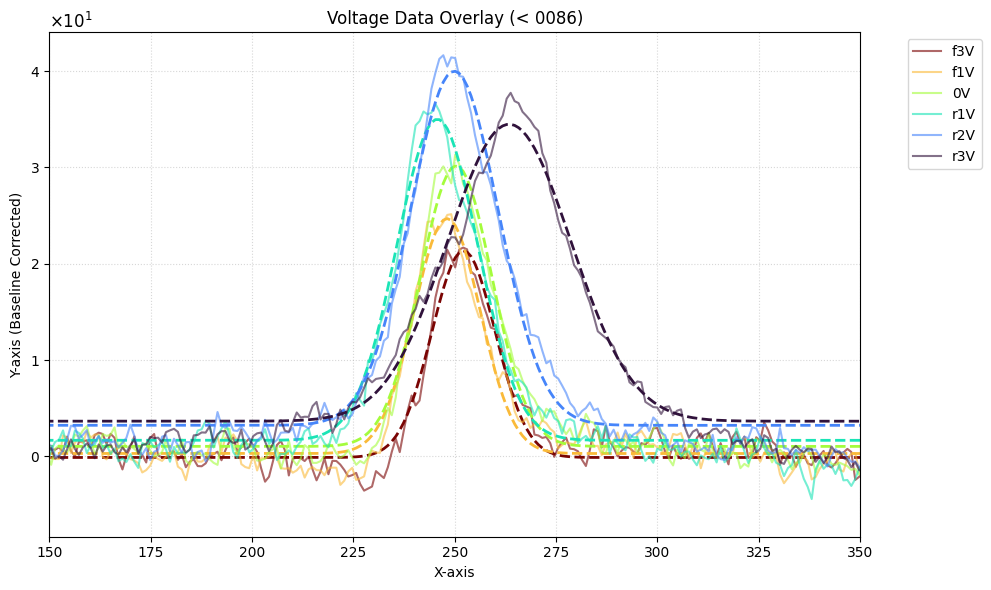

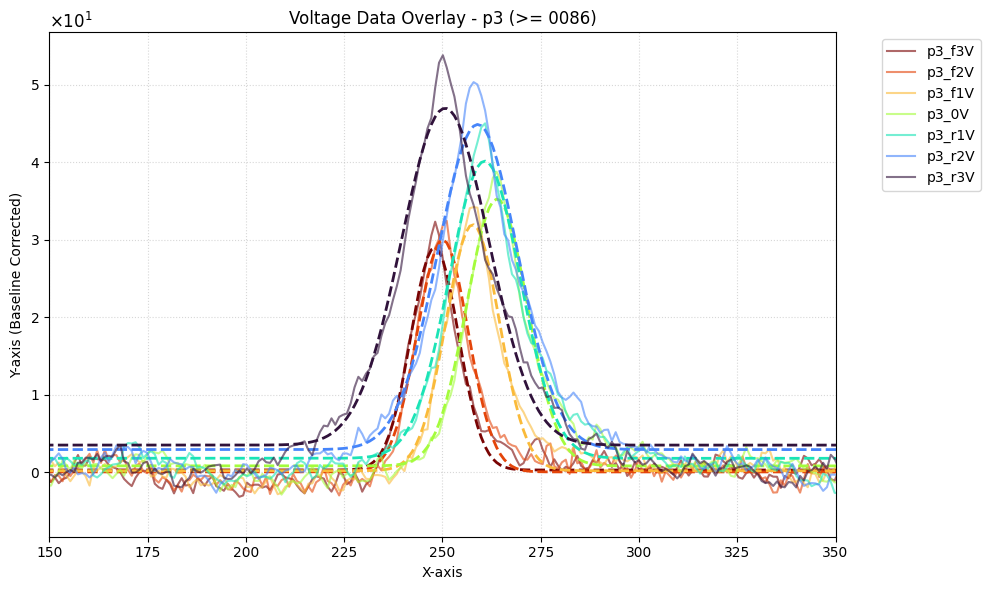

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピークフィッティング用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)

def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.turbo

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []
        peak_xs = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】まずベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】ベースラインを引いたデータに対して、200~300でガウシアンフィットして位置合わせ用ピークを特定
            mask_peak = (x >= 225) & (x <= 275)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))
            peak_xs.append(peak_x)

        if not data_list:
            continue

        # 【手順3】ピーク位置を合わせる
        target_peak_x = np.mean(peak_xs)
        base_x = data_list[0][0]
        common_x = np.linspace(base_x.min(), base_x.max(), len(base_x))
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            shift_amount = target_peak_x - peak_x
            shifted_x = x + shift_amount

            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 【手順4】横軸を揃えた状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        line_color = cmap(norm(eff_v))

        # 【手順5】平均データ（実線）のプロット
        plt.plot(valid_x, valid_y, label=label, color=line_color, linewidth=1.5, alpha=0.6)

        # 【手順6】平均データに対して再度ガウシアンフィットを行い、関数をプロット（点線）
        mask_avg_peak = (valid_x >= 200) & (valid_x <= 300)
        if np.any(mask_avg_peak):
            x_avg = valid_x[mask_avg_peak]
            y_avg = valid_y[mask_avg_peak]

            a_guess = y_avg.max() - y_avg.min()
            mu_guess = x_avg[np.argmax(y_avg)]
            sigma_guess = 10.0
            c_guess = y_avg.min()
            p0 = [a_guess, mu_guess, sigma_guess, c_guess]

            try:
                popt_avg, _ = curve_fit(gaussian, x_avg, y_avg, p0=p0, maxfev=10000)
                # フィットしたガウス関数をプロット (凡例は重複を避けるためNone)
                plt.plot(valid_x, gaussian(valid_x, *popt_avg), color=line_color, linestyle='--', linewidth=2.0)
            except RuntimeError:
                pass

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)
    plt.xlim(150,350)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

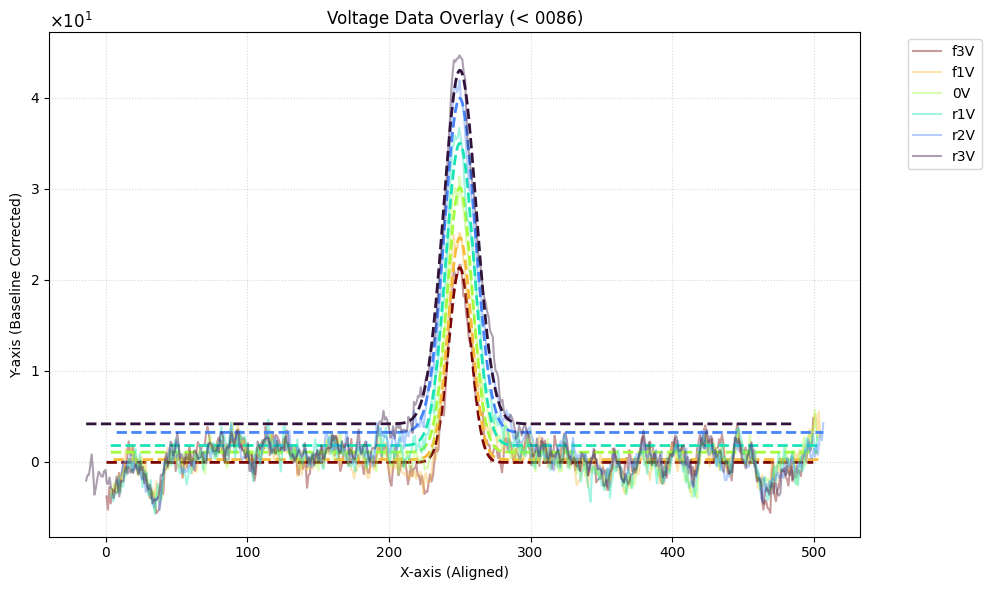

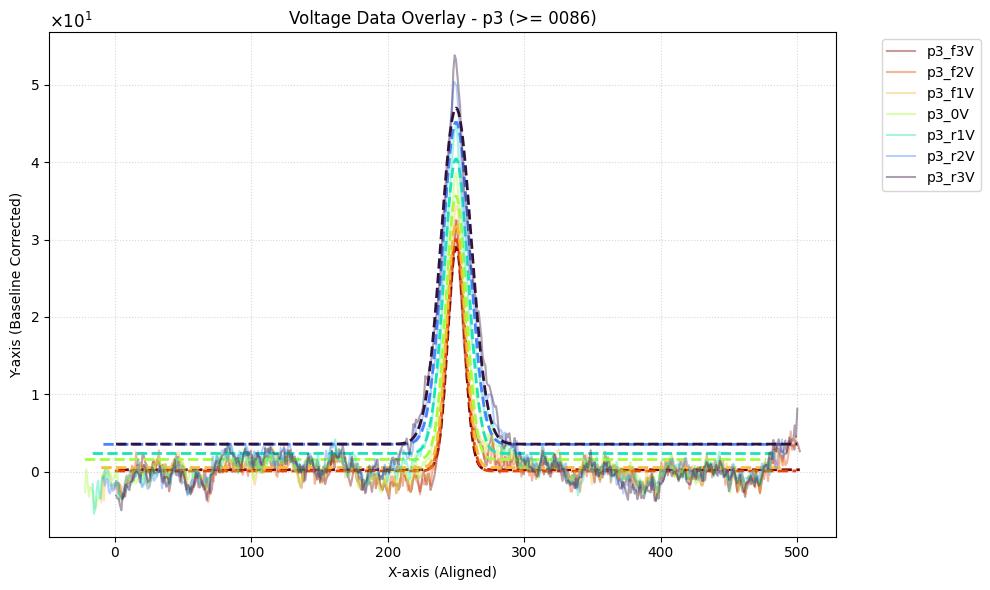

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピークフィッティング用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)


def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.turbo

    # ★ 変更点：すべてのデータのピークを強制的に X=250 の位置に揃える
    GLOBAL_PEAK_X = 250.0

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】生データからベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】200~300でガウシアンフィットして、このファイルの「実際のピークX座標」を特定
            mask_peak = (x >= 200) & (x <= 300)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))

        if not data_list:
            continue

        # 【手順3】すべてのグラフの横軸が GLOBAL_PEAK_X (250) で揃うように補間・平均化
        # 代表として最初のデータのシフト後のX軸を共通X軸として採用
        base_x, _, base_peak_x = data_list[0]
        common_x = base_x - base_peak_x + GLOBAL_PEAK_X
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            # 実際のピークを GLOBAL_PEAK_X (250) に移動させるシフト量
            shifted_x = x - peak_x + GLOBAL_PEAK_X

            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 横軸が完全に揃った状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        line_color = cmap(norm(eff_v))

        # 【手順4】平均データ（実線）のプロット (透明度を下げて点線を目立たせる)
        plt.plot(valid_x, valid_y, label=label, color=line_color, linewidth=1.5, alpha=0.4)

        # 【手順5】アライメント済みの平均データに対して再度ガウシアンフィット（点線）
        # ピークは250に揃っているので、200~300の範囲でフィット
        mask_avg_peak = (valid_x >= 200) & (valid_x <= 300)
        if np.any(mask_avg_peak):
            x_avg = valid_x[mask_avg_peak]
            y_avg = valid_y[mask_avg_peak]

            a_guess = y_avg.max() - y_avg.min()
            mu_guess = 250.0  # ピーク位置は250付近になるはず
            sigma_guess = 10.0
            c_guess = y_avg.min()
            p0 = [a_guess, mu_guess, sigma_guess, c_guess]

            try:
                popt_avg, _ = curve_fit(gaussian, x_avg, y_avg, p0=p0, maxfev=10000)
                plt.plot(valid_x, gaussian(valid_x, *popt_avg), color=line_color, linestyle='--', linewidth=2.0)
            except RuntimeError:
                pass

    plt.xlabel("X-axis (Aligned)")
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)
    plt.xlim(150,350)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

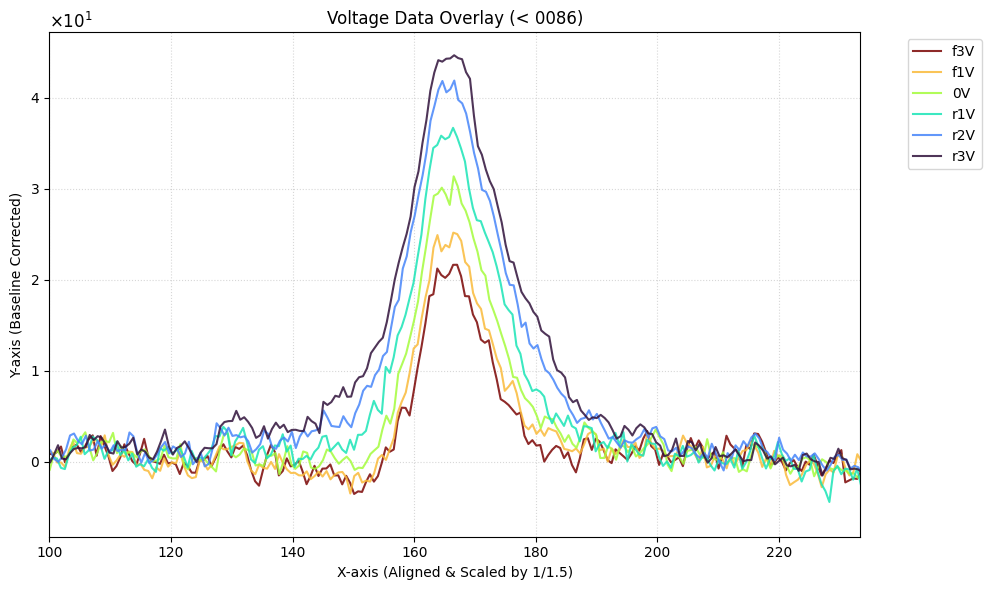

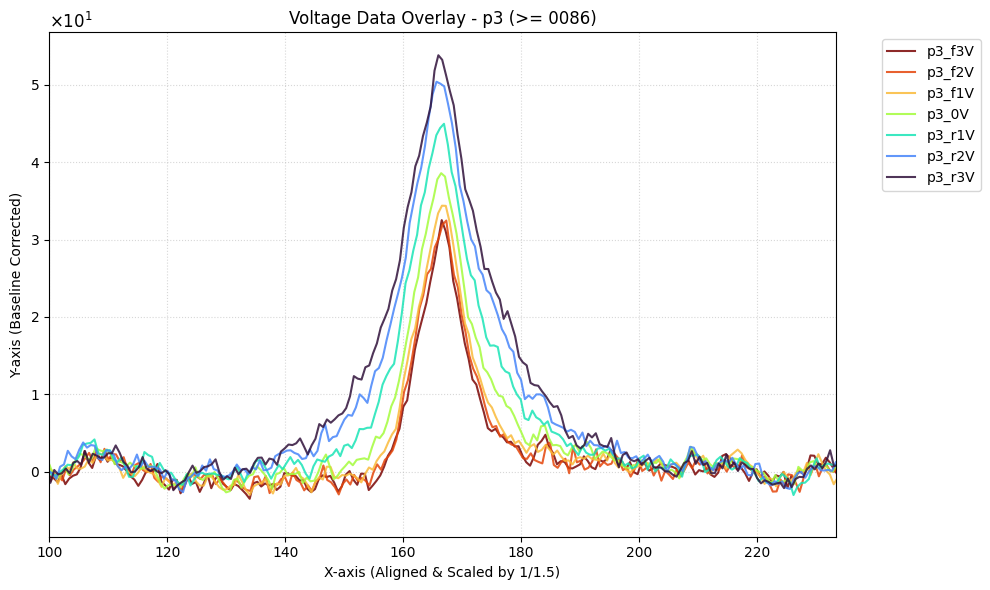

In [ ]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ガウス関数 (ピーク位置特定用) - 構文エラー(2 * sigma)を修正
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_main = {}
grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)
        else:
            if label_str not in grouped_main:
                grouped_main[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_main[label_str]['files'].append(file_path)

def process_and_plot(grouped_data, title):
    if not grouped_data:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        display_label = f"p3_{label}" if "p3" in title else label
        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    voltages = [item[1] for item in plot_items]
    vmin, vmax = min(voltages), max(voltages)
    if vmin == vmax: vmax += 1e-9

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.turbo

    # すべてのデータのピークを強制的に X=250 の位置に揃える
    GLOBAL_PEAK_X = 250.0

    plt.figure(figsize=(10, 6))

    for label, eff_v, files in plot_items:
        data_list = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】生データからベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】200~300でガウシアンフィットして、このファイルの「実際のピークX座標」を特定
            mask_peak = (x >= 200) & (x <= 300)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                # 構文エラー修正 (-) を追加
                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))

        if not data_list:
            continue

        # 【手順3】すべてのグラフの横軸が GLOBAL_PEAK_X (250) で揃うように補間・平均化
        base_x, _, base_peak_x = data_list[0]
        common_x = base_x - base_peak_x + GLOBAL_PEAK_X
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            # 実際のピークを GLOBAL_PEAK_X (250) に移動させるシフト量
            shifted_x = x - peak_x + GLOBAL_PEAK_X

            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 横軸が完全に揃った状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        line_color = cmap(norm(eff_v))

        # 【手順4】平均データ（実線）のプロット
        # 横軸を1.5分の1にするため、valid_x / 1.5 をプロット
        plt.plot(valid_x / 1.5, valid_y, label=label, color=line_color, linewidth=1.5, alpha=0.85)

    plt.xlabel("X-axis (Aligned & Scaled by 1/1.5)")
    plt.ylabel("Y-axis (Baseline Corrected)")
    plt.title(title)

    # 横軸のスケールに合わせて、表示範囲も1.5分の1に調整 (100, 233.33...)
    plt.xlim(150 / 1.5, 350 / 1.5)

    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_main:
    process_and_plot(grouped_main, "Voltage Data Overlay (< 0086)")

if grouped_p3:
    process_and_plot(grouped_p3, "Voltage Data Overlay - p3 (>= 0086)")

In [2]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# --- フォントや枠線の全体設定（文字を太く大きく） ---
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 16
plt.rcParams["axes.linewidth"] = 2.0

# ガウス関数 (ピーク位置特定用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        # p3のみ処理する
        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)

def process_and_plot(grouped_data):
    if not grouped_data:
        print("該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        # 凡例の f を forward, r を reverse に変更
        if label.startswith('r'):
            display_label = label.replace('r', 'reverse ', 1)
        elif label.startswith('f'):
            display_label = label.replace('f', 'forward ', 1)
        else:
            display_label = label

        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    # 電圧の最大値(正)と最小値(負)を取得してカラーマップの基準にする
    voltages = [item[1] for item in plot_items]
    max_pos = max([v for v in voltages if v > 0], default=1.0)
    max_neg = min([v for v in voltages if v < 0], default=-1.0)

    # すべてのデータのピークを強制的に X=250 の位置に揃える
    GLOBAL_PEAK_X = 250.0

    # グラフを横長に設定 (12, 6)
    plt.figure(figsize=(12, 6))

    for display_label, eff_v, files in plot_items:
        data_list = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】生データからベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】200~300でガウシアンフィットして、このファイルの「実際のピークX座標」を特定
            mask_peak = (x >= 200) & (x <= 300)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))

        if not data_list:
            continue

        # 【手順3】すべてのグラフの横軸が GLOBAL_PEAK_X (250) で揃うように補間・平均化
        base_x, _, base_peak_x = data_list[0]
        common_x = base_x - base_peak_x + GLOBAL_PEAK_X
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            shifted_x = x - peak_x + GLOBAL_PEAK_X
            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 横軸が完全に揃った状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # --- 電圧値に応じた線の色の設定 ---
        if eff_v == 0:
            line_color = 'black'
        elif eff_v > 0:
            ratio = eff_v / max_pos
            line_color = cm.Blues(0.4 + 0.6 * ratio)
        else:
            ratio = abs(eff_v) / abs(max_neg)
            line_color = cm.Reds(0.4 + 0.6 * ratio)

        # 【手順4】平均データ（実線）のプロット
        # ピーク位置 (250) を 0 にシフトさせてから 1.5 で割る
        x_plot = (valid_x - GLOBAL_PEAK_X) / 1.5
        plt.plot(x_plot, valid_y, label=display_label, color=line_color, linewidth=2.5, alpha=0.85)

    # --- 軸ラベル・表示設定 ---
    plt.xlabel("Distance [nm]", fontsize=18, fontweight='bold')
    plt.ylabel("Projected electric field [(V/nm)*nm]", fontsize=18, fontweight='bold')

    # 横軸の表示範囲をピーク位置0に合わせて調整 (-100/1.5 から 100/1.5)
    plt.xlim(-100 / 1.5, 100 / 1.5)

    # y軸の指数表記をオフにし、普通の数値で表示
    plt.ticklabel_format(style='plain', axis='y')

    # 目盛りを内向きにし、太く大きく設定
    plt.tick_params(axis='both', which='major', direction='in',
                    labelsize=16, width=2.0, length=8,
                    top=True, right=True)

    # 凡例の表示（グラフの内側に配置）
    plt.legend(loc='best', fontsize=14)

    # グリッドは不要
    plt.grid(False)

    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_p3:
    process_and_plot(grouped_p3)

Mounted at /content/drive
検出された .npz ファイル数: 46


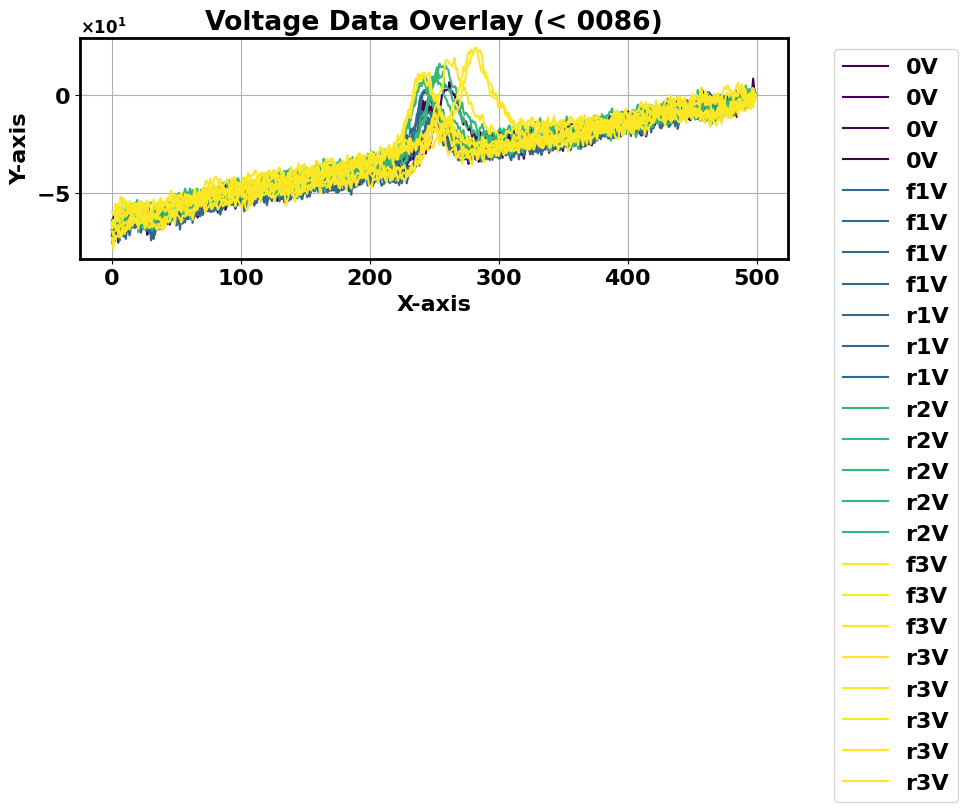

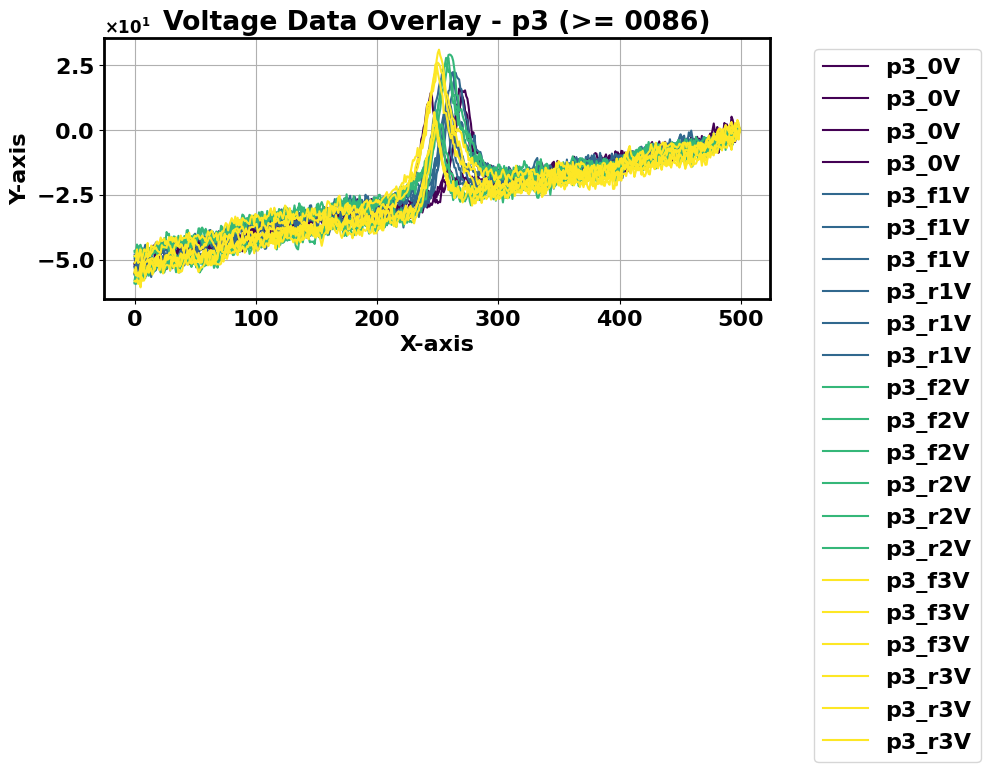

In [3]:
import os
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from google.colab import drive

# Googleドライブをマウント
drive.mount('/content/drive')

# データがあるフォルダのパスを指定
data_dir = "/content/drive/MyDrive/20261022profile"

# .npz ファイルを取得
npz_files = glob.glob(os.path.join(data_dir, "*.npz"))
print(f"検出された .npz ファイル数: {len(npz_files)}")

# 正規表現パターン
volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V' # 電圧抽出用
num_pattern = r'(\d{4})'                   # 4桁の数字抽出用

# データを分けるためのリスト
group_main = [] # 0085以下（または4桁の数字がない）のファイル
group_p3 = []   # 0086以上のファイル (p3)

for file_path in npz_files:
    # フォルダ名(20261022profile)の数字を誤検出しないようファイル名のみ取得
    file_name = os.path.basename(file_path)

    volt_match = re.search(volt_pattern, file_name)
    num_match = re.search(num_pattern, file_name)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # 4桁の数字があるか確認し、0086以上か判定
        is_p3 = False
        if num_match:
            file_num = int(num_match.group(1)) # 例: '0086' -> 86
            if file_num >= 86:
                is_p3 = True

        # 条件に応じて別々のリストに格納
        if is_p3:
            group_p3.append((file_path, f"p3_{label_str}", voltage_val))
        else:
            group_main.append((file_path, label_str, voltage_val))


# グラフを描画する共通関数
def plot_group(data_group, title):
    if not data_group:
        print(f"[{title}] に該当するデータはありませんでした。")
        return

    # 電圧値でソート
    data_group.sort(key=lambda x: x[2])

    voltages = [info[2] for info in data_group]
    norm = mcolors.Normalize(vmin=min(voltages), vmax=max(voltages))
    cmap = cm.viridis

    plt.figure(figsize=(10, 6))

    for file_path, label, voltage in data_group:
        line_color = cmap(norm(voltage))

        with np.load(file_path) as data:
            keys = data.files
            if len(keys) >= 2:
                x = data[keys[0]]
                y = data[keys[1]]
            else:
                y = data[keys[0]]
                x = np.arange(len(y))

        plt.plot(x, y, label=label, color=line_color)

    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    plt.title(title)

    # Y軸を指数表記にする設定
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0), useMathText=True)
    plt.gca().yaxis.get_offset_text().set_fontsize(12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# --- それぞれ別々のグラフとしてプロットを実行 ---
if group_main:
    plot_group(group_main, "Voltage Data Overlay (< 0086)")

if group_p3:
    plot_group(group_p3, "Voltage Data Overlay - p3 (>= 0086)")

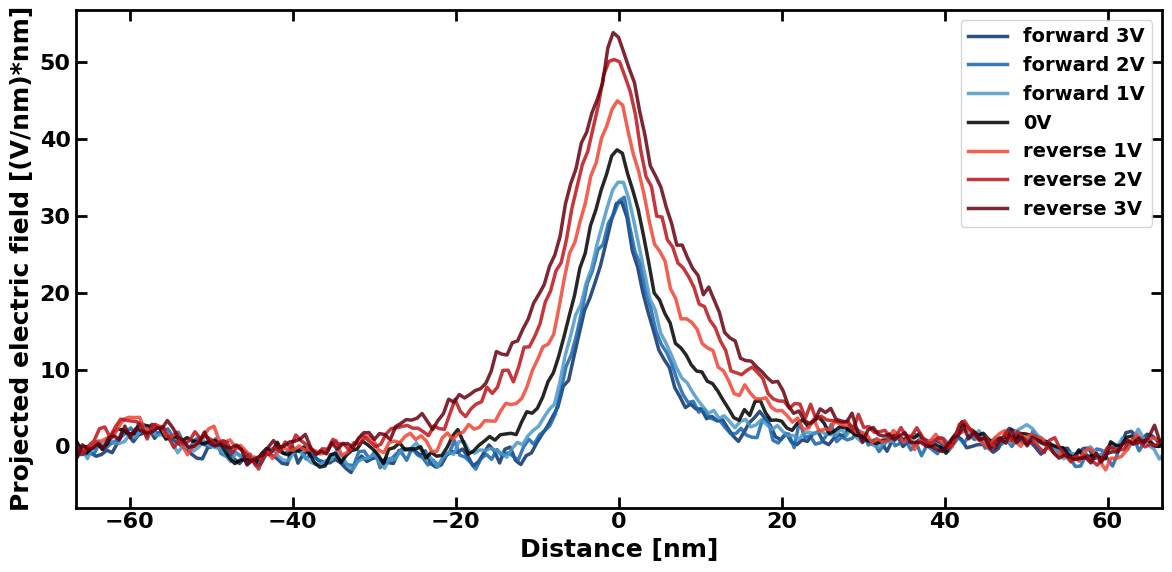

In [4]:
import os
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# --- フォントや枠線の全体設定（文字を太く大きく） ---
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 16
plt.rcParams["axes.linewidth"] = 2.0

# ガウス関数 (ピーク位置特定用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# データがあるフォルダから .npz ファイルを取得
data_dir = "/content/drive/MyDrive/20261022profile"
npz_files = glob.glob(os.path.join(data_dir, "*.npz"))

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_p3 = {}

for file_path in npz_files:
    # ファイル名のみ抽出して正規表現を適用
    file_name = os.path.basename(file_path)

    volt_match = re.search(volt_pattern, file_name)
    num_match = re.search(num_pattern, file_name)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        # p3のみ処理する
        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)

def process_and_plot(grouped_data):
    if not grouped_data:
        print("該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        # 凡例の f を forward, r を reverse に変更
        if label.startswith('r'):
            display_label = label.replace('r', 'reverse ', 1)
        elif label.startswith('f'):
            display_label = label.replace('f', 'forward ', 1)
        else:
            display_label = label

        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    # 電圧の最大値(正)と最小値(負)を取得してカラーマップの基準にする
    voltages = [item[1] for item in plot_items]
    max_pos = max([v for v in voltages if v > 0], default=1.0)
    max_neg = min([v for v in voltages if v < 0], default=-1.0)

    # すべてのデータのピークを強制的に X=250 の位置に揃える
    GLOBAL_PEAK_X = 250.0

    # グラフを横長に設定 (12, 6)
    plt.figure(figsize=(12, 6))

    for display_label, eff_v, files in plot_items:
        data_list = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】生データからベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】200~300でガウシアンフィットして、このファイルの「実際のピークX座標」を特定
            mask_peak = (x >= 200) & (x <= 300)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))

        if not data_list:
            continue

        # 【手順3】すべてのグラフの横軸が GLOBAL_PEAK_X (250) で揃うように補間・平均化
        base_x, _, base_peak_x = data_list[0]
        common_x = base_x - base_peak_x + GLOBAL_PEAK_X
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            shifted_x = x - peak_x + GLOBAL_PEAK_X
            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 横軸が完全に揃った状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # --- 電圧値に応じた線の色の設定 ---
        if eff_v == 0:
            line_color = 'black'
        elif eff_v > 0:
            ratio = eff_v / max_pos
            line_color = cm.Blues(0.4 + 0.6 * ratio)
        else:
            ratio = abs(eff_v) / abs(max_neg)
            line_color = cm.Reds(0.4 + 0.6 * ratio)

        # 【手順4】平均データ（実線）のプロット
        # ピーク位置 (250) を 0 にシフトさせてから 1.5 で割る
        x_plot = (valid_x - GLOBAL_PEAK_X) / 1.5
        plt.plot(x_plot, valid_y, label=display_label, color=line_color, linewidth=2.5, alpha=0.85)

    # --- 軸ラベル・表示設定 ---
    plt.xlabel("Distance [nm]", fontsize=18, fontweight='bold')
    plt.ylabel("Projected electric field [(V/nm)*nm]", fontsize=18, fontweight='bold')

    # 横軸の表示範囲をピーク位置0に合わせて調整 (-100/1.5 から 100/1.5)
    plt.xlim(-100 / 1.5, 100 / 1.5)

    # y軸の指数表記をオフにし、普通の数値で表示
    plt.ticklabel_format(style='plain', axis='y')

    # 目盛りを内向きにし、太く大きく設定
    plt.tick_params(axis='both', which='major', direction='in',
                    labelsize=16, width=2.0, length=8,
                    top=True, right=True)

    # 凡例の表示（グラフの内側に配置）
    plt.legend(loc='best', fontsize=14)

    # グリッドは不要
    plt.grid(False)

    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_p3:
    process_and_plot(grouped_p3)

In [1]:
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid  # 積分計算用に追加

# --- フォントや枠線の全体設定（文字を太く大きく） ---
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 16
plt.rcParams["axes.linewidth"] = 2.0

# ガウス関数 (ピーク位置特定用)
def gaussian(x, a, mu, sigma, c):
    # 修正: 2sigma**2 -> 2 * sigma**2
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# .npz ファイルを取得
npz_files = glob.glob("*.npz")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_p3 = {}

for file_path in npz_files:
    volt_match = re.search(volt_pattern, file_path)
    num_match = re.search(num_pattern, file_path)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        # p3のみ処理する
        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)

def process_and_plot(grouped_data):
    if not grouped_data:
        print("該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        # 凡例の f を forward, r を reverse に変更
        if label.startswith('r'):
            display_label = label.replace('r', 'reverse ', 1)
        elif label.startswith('f'):
            display_label = label.replace('f', 'forward ', 1)
        else:
            display_label = label

        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    # 電圧の最大値(正)と最小値(負)を取得してカラーマップの基準にする
    voltages = [item[1] for item in plot_items]
    max_pos = max([v for v in voltages if v > 0], default=1.0)
    max_neg = min([v for v in voltages if v < 0], default=-1.0)

    # すべてのデータのピークを強制的に X=250 の位置に揃える
    GLOBAL_PEAK_X = 250.0

    # グラフを横長に設定 (12, 6)
    plt.figure(figsize=(12, 6))

    for display_label, eff_v, files in plot_items:
        data_list = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】生データからベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】200~300でガウシアンフィットして、このファイルの「実際のピークX座標」を特定
            mask_peak = (x >= 200) & (x <= 300)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                # 修正: y_peak.max() - y_peak.min() にマイナス記号を追加
                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))

        if not data_list:
            continue

        # 【手順3】すべてのグラフの横軸が GLOBAL_PEAK_X (250) で揃うように補間・平均化
        base_x, _, base_peak_x = data_list[0]
        common_x = base_x - base_peak_x + GLOBAL_PEAK_X
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            shifted_x = x - peak_x + GLOBAL_PEAK_X
            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 横軸が完全に揃った状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # --- 電圧値に応じた線の色の設定 ---
        if eff_v == 0:
            line_color = 'black'
        elif eff_v > 0:
            ratio = eff_v / max_pos
            # 修正: 0.6 * ratio にアスタリスクを追加
            line_color = cm.Blues(0.4 + 0.6 * ratio)
        else:
            ratio = abs(eff_v) / abs(max_neg)
            # 修正: 0.6 * ratio にアスタリスクを追加
            line_color = cm.Reds(0.4 + 0.6 * ratio)

        # 【手順4】平均データ（実線）のプロット
        # ピーク位置 (250) を 0 にシフトさせてから 1.5 で割る
        x_plot = (valid_x - GLOBAL_PEAK_X) / 1.5

        # --- 追加: 電場の積分と電位のゼロ点補正 ---
        # 物理的な定義 (V = -∫E dx) に基づきマイナスをつけています（不要なら外してください）
        potential_y = -cumulative_trapezoid(valid_y, x_plot, initial=0)

        # 真ん中(x_plot=0)から右40nm〜60nmの範囲の平均を計算
        ref_mask = (x_plot >= 40) & (x_plot <= 60)
        if np.any(ref_mask):
            zero_ref = np.mean(potential_y[ref_mask])
        else:
            zero_ref = 0.0

        # 基準値を引いて 40〜60nm の平均を 0V とする
        potential_y = potential_y - zero_ref

        # yをvalid_yからpotential_yに変更してプロット
        plt.plot(x_plot, potential_y, label=display_label, color=line_color, linewidth=2.5, alpha=0.85)

    # --- 軸ラベル・表示設定 ---
    plt.xlabel("Distance [nm]", fontsize=18, fontweight='bold')
    # 電位のプロットに合わせてラベルを変更
    plt.ylabel("Potential [V]", fontsize=18, fontweight='bold')

    # 横軸の表示範囲をピーク位置0に合わせて調整 (-100/1.5 から 100/1.5)
    plt.xlim(-100 / 1.5, 100 / 1.5)

    # y軸の指数表記をオフにし、普通の数値で表示
    plt.ticklabel_format(style='plain', axis='y')

    # 目盛りを内向きにし、太く大きく設定
    plt.tick_params(axis='both', which='major', direction='in',
                    labelsize=16, width=2.0, length=8,
                    top=True, right=True)

    # 凡例の表示（グラフの内側に配置）
    plt.legend(loc='best', fontsize=14)

    # グリッドは不要
    plt.grid(False)

    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_p3:
    process_and_plot(grouped_p3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
検出された .npz ファイル数: 46


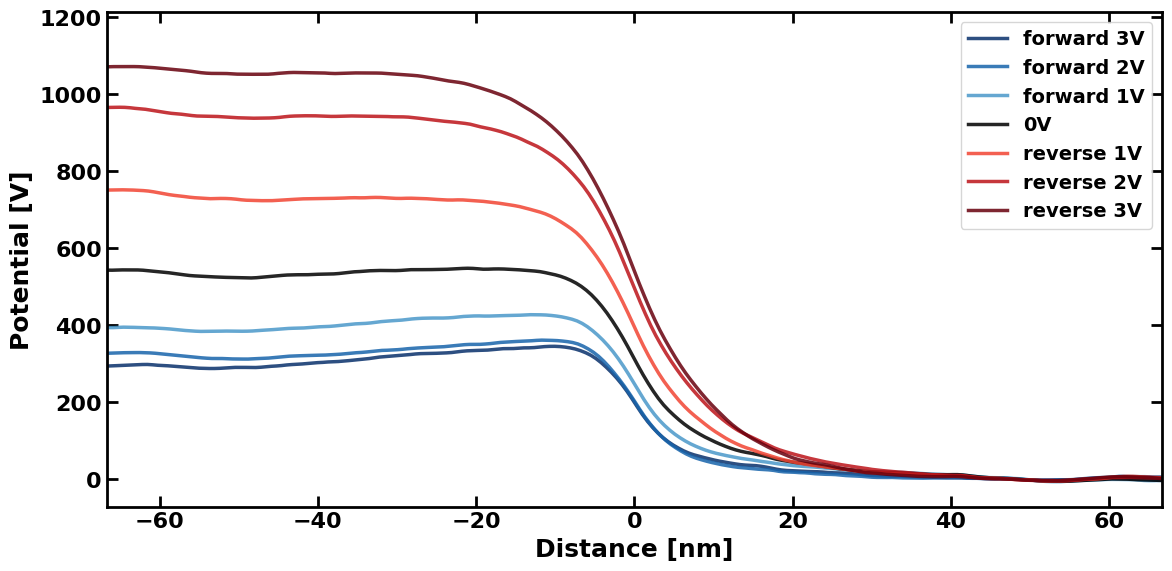

In [5]:
import os
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
from google.colab import drive

# Googleドライブをマウント（既にマウント済みの場合はそのままスキップされます）
drive.mount('/content/drive')

# --- フォントや枠線の全体設定（文字を太く大きく） ---
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 16
plt.rcParams["axes.linewidth"] = 2.0

# ガウス関数 (ピーク位置特定用)
def gaussian(x, a, mu, sigma, c):
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# データがあるフォルダから .npz ファイルを取得
data_dir = "/content/drive/MyDrive/20261022profile"
npz_files = glob.glob(os.path.join(data_dir, "*.npz"))
print(f"検出された .npz ファイル数: {len(npz_files)}")

volt_pattern = r'([rf]?([-+]?\d*\.?\d+))V'
num_pattern = r'(\d{4})'

grouped_p3 = {}

for file_path in npz_files:
    # フォルダ名(20261022profile)の数字を誤検出しないようファイル名のみ取得
    file_name = os.path.basename(file_path)

    volt_match = re.search(volt_pattern, file_name)
    num_match = re.search(num_pattern, file_name)

    if volt_match:
        label_str = volt_match.group(0)
        voltage_val = float(volt_match.group(2))

        # r(逆電圧)はマイナス、f(順電圧)はプラスとする
        if label_str.startswith('r'):
            effective_v = -abs(voltage_val)
        elif label_str.startswith('f'):
            effective_v = abs(voltage_val)
        else:
            effective_v = voltage_val

        is_p3 = False
        if num_match and int(num_match.group(1)) >= 86:
            is_p3 = True

        # p3のみ処理する
        if is_p3:
            if label_str not in grouped_p3:
                grouped_p3[label_str] = {'files': [], 'eff_v': effective_v}
            grouped_p3[label_str]['files'].append(file_path)

def process_and_plot(grouped_data):
    if not grouped_data:
        print("該当するデータはありませんでした。")
        return

    plot_items = []
    for label, info in grouped_data.items():
        # 凡例の f を forward, r を reverse に変更
        if label.startswith('r'):
            display_label = label.replace('r', 'reverse ', 1)
        elif label.startswith('f'):
            display_label = label.replace('f', 'forward ', 1)
        else:
            display_label = label

        plot_items.append((display_label, info['eff_v'], info['files']))

    # 降順ソート (f -> 0V -> r の順)
    plot_items.sort(key=lambda x: x[1], reverse=True)

    # 電圧の最大値(正)と最小値(負)を取得してカラーマップの基準にする
    voltages = [item[1] for item in plot_items]
    max_pos = max([v for v in voltages if v > 0], default=1.0)
    max_neg = min([v for v in voltages if v < 0], default=-1.0)

    # すべてのデータのピークを強制的に X=250 の位置に揃える
    GLOBAL_PEAK_X = 250.0

    # グラフを横長に設定 (12, 6)
    plt.figure(figsize=(12, 6))

    for display_label, eff_v, files in plot_items:
        data_list = []

        # --- 1ファイルごとの処理 ---
        for file_path in files:
            with np.load(file_path) as data:
                keys = data.files
                if len(keys) >= 2:
                    x = data[keys[0]]
                    y = data[keys[1]]
                else:
                    y = data[keys[0]]
                    x = np.arange(len(y))

            # 【手順1】生データからベースライン補正（0~150, 350~右端）を行う
            base_mask = ((x >= 0) & (x <= 150)) | (x >= 350)
            if np.any(base_mask):
                poly_coeffs = np.polyfit(x[base_mask], y[base_mask], 1)
                baseline_y = np.polyval(poly_coeffs, x)
                y_corrected = y - baseline_y
            else:
                y_corrected = y

            # 【手順2】200~300でガウシアンフィットして、このファイルの「実際のピークX座標」を特定
            mask_peak = (x >= 200) & (x <= 300)
            if np.any(mask_peak):
                x_peak = x[mask_peak]
                y_peak = y_corrected[mask_peak]

                a_guess = y_peak.max() - y_peak.min()
                mu_guess = x_peak[np.argmax(y_peak)]
                sigma_guess = 10.0
                c_guess = y_peak.min()
                p0 = [a_guess, mu_guess, sigma_guess, c_guess]

                try:
                    popt, _ = curve_fit(gaussian, x_peak, y_peak, p0=p0, maxfev=10000)
                    peak_x = popt[1]
                except RuntimeError:
                    peak_x = mu_guess
            else:
                peak_x = np.mean(x)

            data_list.append((x, y_corrected, peak_x))

        if not data_list:
            continue

        # 【手順3】すべてのグラフの横軸が GLOBAL_PEAK_X (250) で揃うように補間・平均化
        base_x, _, base_peak_x = data_list[0]
        common_x = base_x - base_peak_x + GLOBAL_PEAK_X
        aligned_ys = []

        for x, y_corr, peak_x in data_list:
            shifted_x = x - peak_x + GLOBAL_PEAK_X
            f_interp = interp1d(shifted_x, y_corr, bounds_error=False, fill_value=np.nan)
            aligned_ys.append(f_interp(common_x))

        # 横軸が完全に揃った状態で平均をとる
        mean_y = np.nanmean(aligned_ys, axis=0)

        valid_mask = ~np.isnan(mean_y)
        valid_x = common_x[valid_mask]
        valid_y = mean_y[valid_mask]

        if len(valid_x) == 0:
            continue

        # --- 電圧値に応じた線の色の設定 ---
        if eff_v == 0:
            line_color = 'black'
        elif eff_v > 0:
            ratio = eff_v / max_pos
            line_color = cm.Blues(0.4 + 0.6 * ratio)
        else:
            ratio = abs(eff_v) / abs(max_neg)
            line_color = cm.Reds(0.4 + 0.6 * ratio)

        # 【手順4】平均データ（実線）のプロット
        # ピーク位置 (250) を 0 にシフトさせてから 1.5 で割る
        x_plot = (valid_x - GLOBAL_PEAK_X) / 1.5

        # --- 電場の積分と電位のゼロ点補正 ---
        # 物理的な定義 (V = -∫E dx) に基づきマイナスをつけています（不要なら外してください）
        potential_y = -cumulative_trapezoid(valid_y, x_plot, initial=0)

        # 真ん中(x_plot=0)から右40nm〜60nmの範囲の平均を計算
        ref_mask = (x_plot >= 40) & (x_plot <= 60)
        if np.any(ref_mask):
            zero_ref = np.mean(potential_y[ref_mask])
        else:
            zero_ref = 0.0

        # 基準値を引いて 40〜60nm の平均を 0V とする
        potential_y = potential_y - zero_ref

        # yをvalid_yからpotential_yに変更してプロット
        plt.plot(x_plot, potential_y, label=display_label, color=line_color, linewidth=2.5, alpha=0.85)

    # --- 軸ラベル・表示設定 ---
    plt.xlabel("Distance [nm]", fontsize=18, fontweight='bold')
    plt.ylabel("Potential [V]", fontsize=18, fontweight='bold')

    # 横軸の表示範囲をピーク位置0に合わせて調整 (-100/1.5 から 100/1.5)
    plt.xlim(-100 / 1.5, 100 / 1.5)

    # y軸の指数表記をオフにし、普通の数値で表示
    plt.ticklabel_format(style='plain', axis='y')

    # 目盛りを内向きにし、太く大きく設定
    plt.tick_params(axis='both', which='major', direction='in',
                    labelsize=16, width=2.0, length=8,
                    top=True, right=True)

    # 凡例の表示（グラフの内側に配置）
    plt.legend(loc='best', fontsize=14)

    # グリッドは不要
    plt.grid(False)

    plt.tight_layout()
    plt.show()

# --- プロット実行 ---
if grouped_p3:
    process_and_plot(grouped_p3)